# Proyecto final IA — Diagnóstico automotriz (CRISP-ML(Q), fases 1 a 4)

Notebook de experimentación: conversión del JSON a tabla, partición agrupada por componente, comparación de modelos, optimización y evaluación. El servicio (`app/`) reutiliza esta misma lógica en `app/ml/`.

> **Nota de reproducibilidad:** las métricas dependen de qué componentes caen en el conjunto de prueba, y la partición de `StratifiedGroupKFold` cambia entre versiones de scikit-learn. Con `scikit-learn==1.9.1` (ver `requirements.txt`) el hold-out da Accuracy 0.49 / F1 macro 0.49; la CV agrupada anidada del servicio da F1 macro 0.46 ± 0.08.

Dataset tabular generado: 1172 filas x 9 columnas

Distribución de clases (category):
category
Engine Components          180
Electrical System          160
Drivetrain                 132
ABS System                 108
Emissions System           108
Air Conditioning System     96
Cooling System              96
Engine Compartment          72
Fuel System                 60
Liquid Systems              60
Transmission                60
Wheels & Tires              36
Steering                     4
Name: count, dtype: int64

Split verificado sin fuga de datos -> Train: 844 | Test: 288

--- Comparación de Modelos Base (Validación Cruzada Agrupada) ---


             Modelo  Accuracy  F1-Score Macro  Balanced Accuracy
         Linear SVM  0.589473        0.526627           0.551684
Logistic Regression  0.583273        0.496275           0.515278
      Random Forest  0.446561        0.377266           0.395118
            XGBoost  0.423733        0.359145           0.374537
      Decision Tree  0.366268        0.298211           0.336406



Mejores hiperparámetros encontrados: {'clf__C': 5.0, 'tfidf__ngram_range': (1, 1), 'tfidf__sublinear_tf': False}

=== MÉTRICAS FINALES EN TEST (COMPONENTES NO VISTOS) ===
Accuracy:          0.4931
F1-Score Macro:    0.4895
Balanced Accuracy: 0.5013

Reporte de Clasificación por Clase:
                         precision    recall  f1-score   support

             ABS System       0.92      1.00      0.96        24
Air Conditioning System       1.00      1.00      1.00        24
         Cooling System       1.00      0.50      0.67        24
             Drivetrain       0.07      0.03      0.04        36
      Electrical System       1.00      0.67      0.80        36
       Emissions System       1.00      0.44      0.62        36
     Engine Compartment       0.00      0.00      0.00        12
      Engine Components       0.22      0.25      0.24        48
            Fuel System       0.18      0.67      0.28        12
         Liquid Systems       0.07      0.17      0.10        

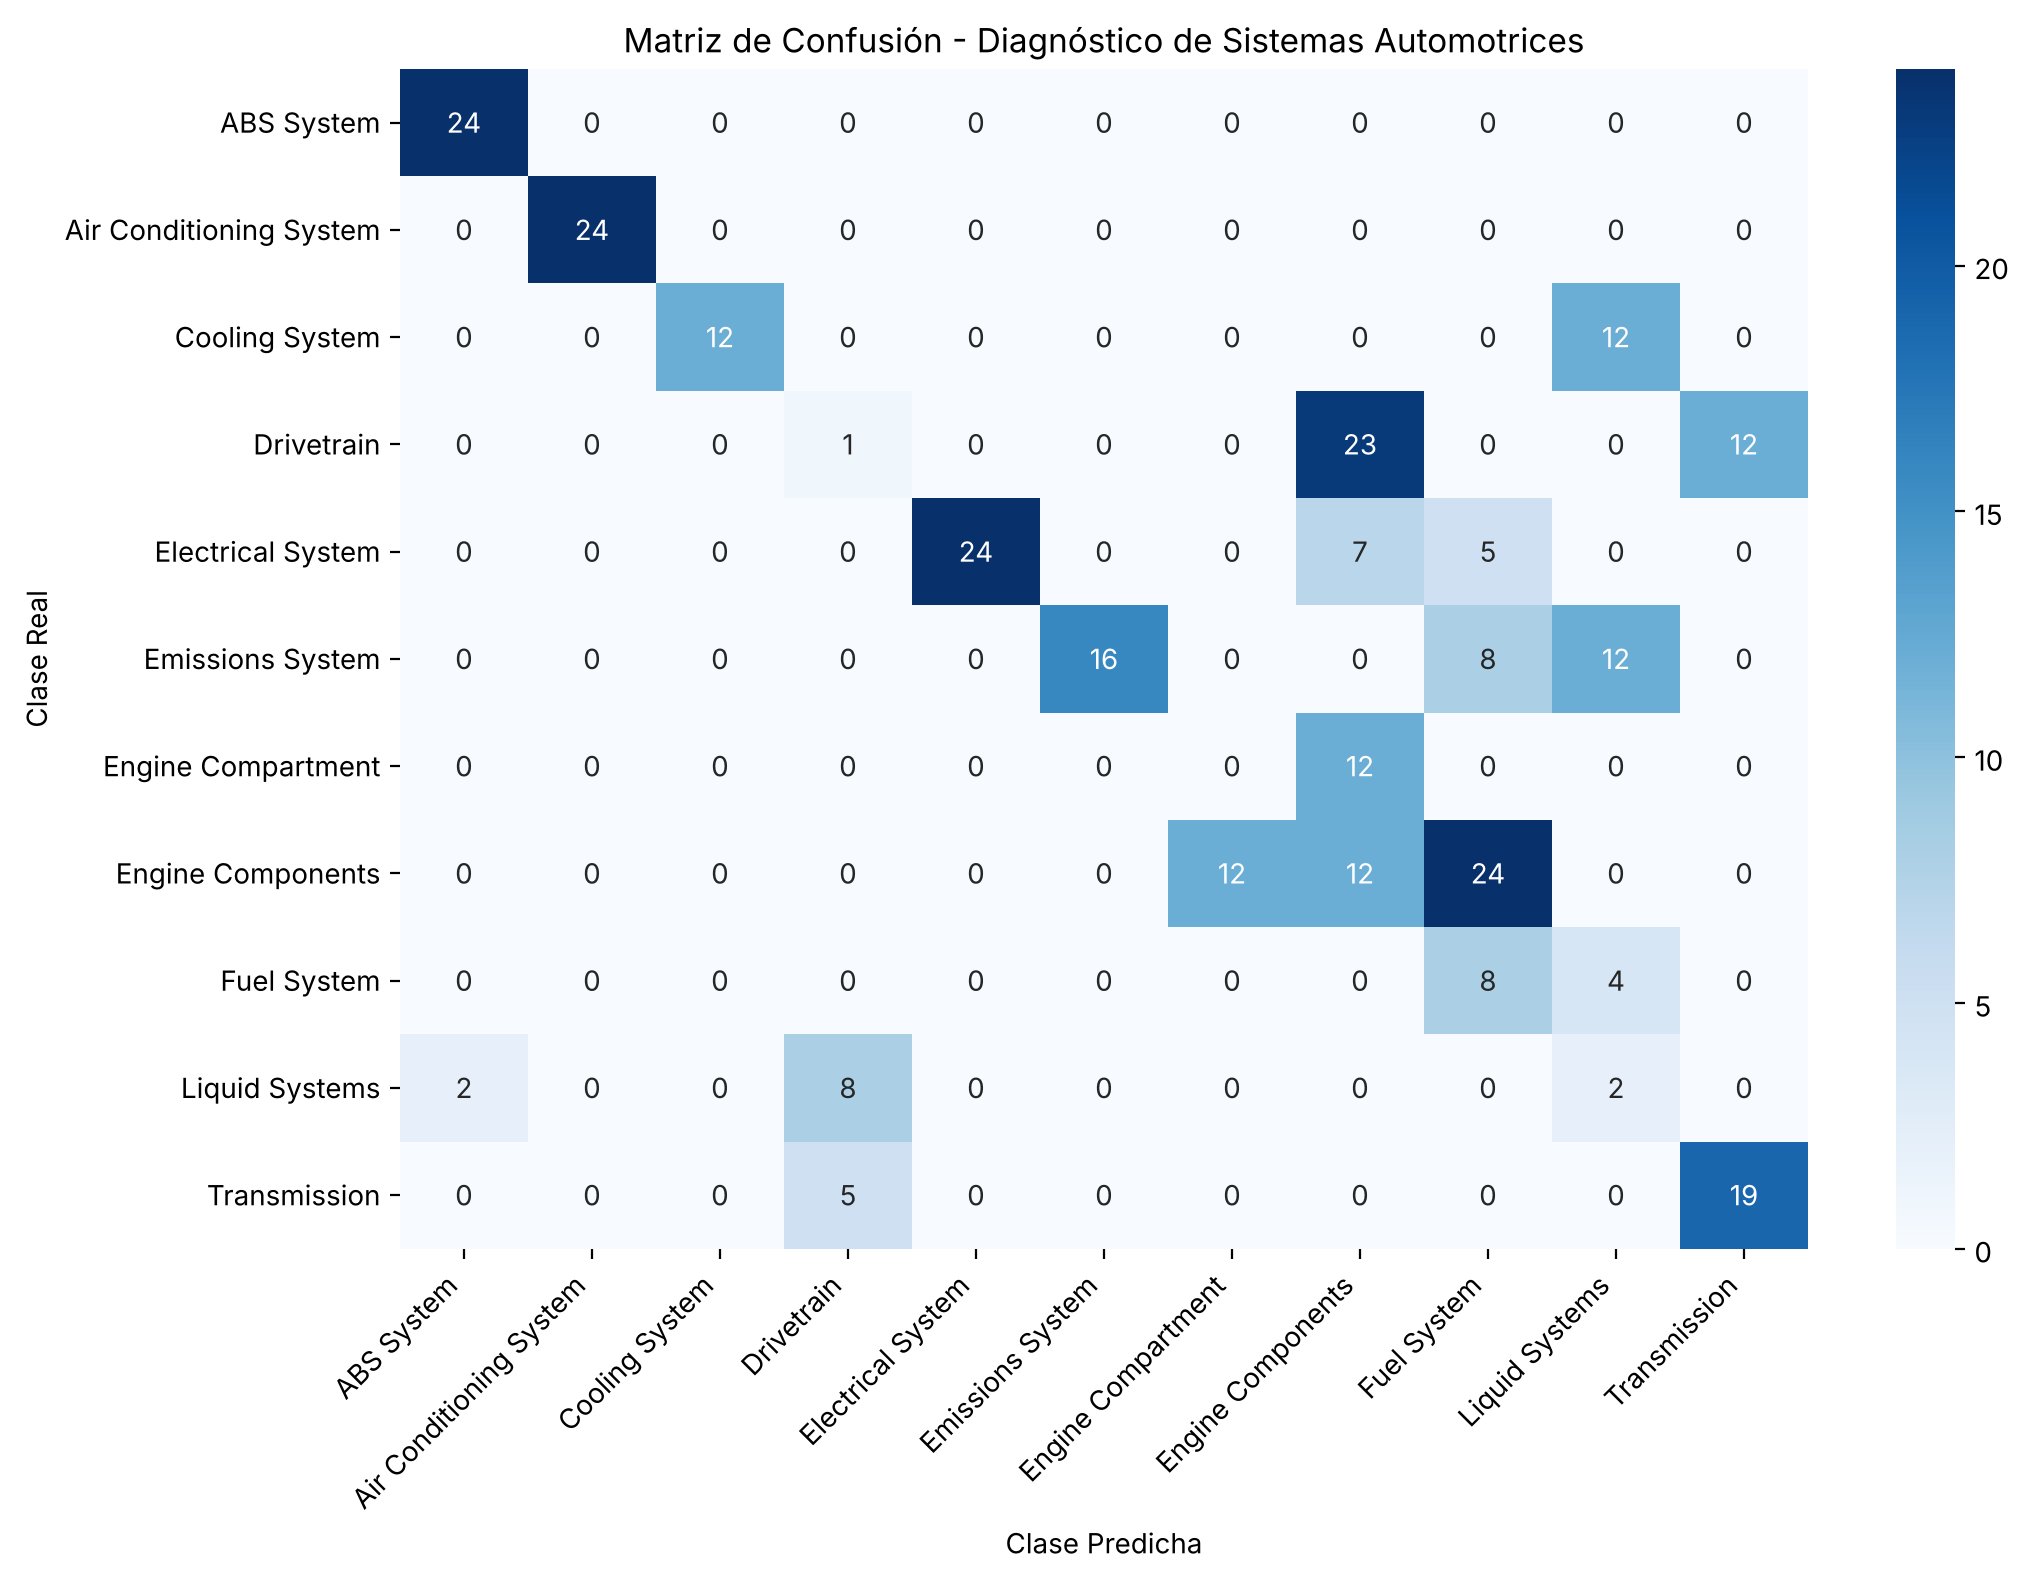


Artefacto exportado correctamente: 'automotive_fault_model.joblib'


In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, cross_validate, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# ==============================================================================
# FASE 1: COMPRENSIÓN DE LOS DATOS Y CONVERSIÓN JSON -> CSV TABULAR
# ==============================================================================
with open('../data/automotive_faults_aktc_obike_et_al.json', 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

rows = []
for idx, item in enumerate(raw_data):
    cat = item['category']
    subcat = item['subcategory']
    syms = item['symptoms']
    step1 = item['diagnosis_steps'][0]
    step2 = item['diagnosis_steps'][1]

    # Generar variantes válidas de síntomas (individuales y combinados)
    sym_variants = syms + [" + ".join(syms)] if len(syms) > 1 else syms
    for s_var in sym_variants:
        for r1 in step1['result']:
            for r2 in step2['result']:
                is_fault = (r1 == step1['result'][0]) or (r2 == step2['result'][0])
                rows.append({
                    'component_id': idx + 1,
                    'category': cat,
                    'subcategory': subcat,
                    'symptoms': s_var,
                    'step_1': step1['step'],
                    'result_1': r1,
                    'step_2': step2['step'],
                    'result_2': r2,
                    'diagnostic_status': 'Falla Confirmada' if is_fault else 'Sin Falla / Normal'
                })

df = pd.DataFrame(rows)
df.to_csv('../data/automotive_faults_tabular.csv', index=False)
print(f"Dataset tabular generado: {df.shape[0]} filas x {df.shape[1]} columnas")
print("\nDistribución de clases (category):")
print(df['category'].value_counts())

# ==============================================================================
# FASE 2: PREPARACIÓN DE DATOS Y PREVENCIÓN DE DATA LEAKAGE
# ==============================================================================
# 1. Filtrar clases con al menos 4 componentes distintos para garantizar
#    representación tanto en entrenamiento como en prueba al agrupar por componente.
cat_comp_counts = df.groupby('category')['component_id'].nunique()
valid_cats = cat_comp_counts[cat_comp_counts >= 4].index
df_clean = df[df['category'].isin(valid_cats)].drop_duplicates().copy()

# 2. Ingeniería de características: unificar síntomas y resultados de inspección
def build_diagnostic_text(dataframe: pd.DataFrame) -> pd.Series:
    return (
        dataframe['symptoms'].fillna('') + " | " +
        dataframe['step_1'].fillna('') + ": " + dataframe['result_1'].fillna('') + " | " +
        dataframe['step_2'].fillna('') + ": " + dataframe['result_2'].fillna('')
    )

X = build_diagnostic_text(df_clean)
y = df_clean['category']
groups = df_clean['component_id']

# 3. División agrupada por component_id (Cero fuga de información)
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

# Verificación de integridad (debe imprimir 0)
overlap = set(groups.iloc[train_idx]).intersection(set(groups.iloc[test_idx]))
assert len(overlap) == 0, "¡Alerta de Data Leakage!"
print(f"\nSplit verificado sin fuga de datos -> Train: {len(X_train)} | Test: {len(X_test)}")

# ==============================================================================
# FASE 3: MODELADO (COMPARACIÓN DE CANDIDATOS Y OPTIMIZACIÓN)
# ==============================================================================
# Codificación numérica auxiliar requerida por XGBoost
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)

candidatos = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, class_weight='balanced', random_state=42),
    'Linear SVM': LinearSVC(dual='auto', class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(eval_metric='mlogloss', random_state=42)
}

inner_cv = StratifiedGroupKFold(n_splits=3)
resultados_cv = []

print("\n--- Comparación de Modelos Base (Validación Cruzada Agrupada) ---")
for nombre, clf in candidatos.items():
    pipe = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
        ('clf', clf)
    ])
    target_y = y_train_enc if nombre == 'XGBoost' else y_train
    scores = cross_validate(
        pipe, X_train, target_y, groups=groups_train, cv=inner_cv,
        scoring=['accuracy', 'f1_macro', 'balanced_accuracy'], n_jobs=-1
    )
    resultados_cv.append({
        'Modelo': nombre,
        'Accuracy': scores['test_accuracy'].mean(),
        'F1-Score Macro': scores['test_f1_macro'].mean(),
        'Balanced Accuracy': scores['test_balanced_accuracy'].mean()
    })

df_resultados = pd.DataFrame(resultados_cv).sort_values(by='F1-Score Macro', ascending=False)
print(df_resultados.to_string(index=False))

# Optimización de hiperparámetros sobre el mejor candidato (Logistic Regression)
pipe_opt = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__sublinear_tf': [True, False],
    'clf__C': [0.25, 0.5, 1.0, 2.0, 5.0]
}

grid = GridSearchCV(
    pipe_opt, param_grid, cv=inner_cv, scoring='f1_macro', n_jobs=-1
)
grid.fit(X_train, y_train, groups=groups_train)

best_model = grid.best_estimator_
print("\nMejores hiperparámetros encontrados:", grid.best_params_)

# ==============================================================================
# FASE 4: EVALUACIÓN EN CONJUNTO DE PRUEBA Y ASEGURAMIENTO DE CALIDAD
# ==============================================================================
y_pred = best_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average='macro')
bal_acc = balanced_accuracy_score(y_test, y_pred)

print(f"\n=== MÉTRICAS FINALES EN TEST (COMPONENTES NO VISTOS) ===")
print(f"Accuracy:          {acc:.4f}")
print(f"F1-Score Macro:    {f1_macro:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")
print("\nReporte de Clasificación por Clase:")
print(classification_report(y_test, y_pred, zero_division=0))

# Gráfico de Matriz de Confusión
plt.figure(figsize=(11, 8))
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)
plt.title('Matriz de Confusión - Diagnóstico de Sistemas Automotrices')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../docs/matriz_confusion.png', dpi=200)
plt.show()

# ==============================================================================
# EXPORTACIÓN DEL MODELO Y METADATOS PARA EL BACKEND (FASTAPI)
# ==============================================================================
# Entrenar versión final con el 100% de los datos limpios antes de desplegar
best_model.fit(X, y)

artifact = {
    'pipeline': best_model,
    'classes': best_model.classes_.tolist(),
    'best_params': grid.best_params_,
    'metrics': {
        'accuracy': round(float(acc), 4),
        'f1_macro': round(float(f1_macro), 4),
        'balanced_accuracy': round(float(bal_acc), 4),
        'training_samples': int(len(df_clean))
    }
}

joblib.dump(artifact, 'automotive_fault_model.joblib')  # solo referencia: la API versiona sus propios modelos en storage/models/
print("\nArtefacto exportado correctamente: 'automotive_fault_model.joblib'")